# 8. Polynomials
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Runge's phenomenon. Interpolating $f(x)=1/(1+25x^2)$ (black) at $n+1$ equally spaced points (left) produces wild oscillations near the ends that grow with $n$. Interpolating at Chebyshev points (right), which cluster near $\pm1$, converges quickly.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


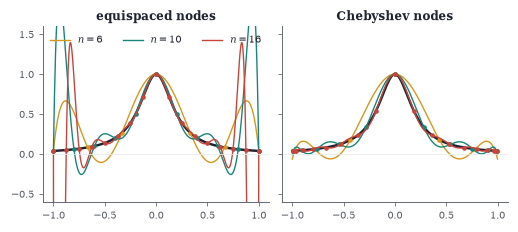

In [2]:
from numpy.polynomial import polynomial as P
f = lambda x: 1 / (1 + 25 * x ** 2)
x = np.linspace(-1, 1, 600)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), sharey=True)
for ax, kind in zip(axs, ["equispaced", "Chebyshev"]):
    ax.plot(x, f(x), color=INK, lw=1.6)
    for n, col in [(6, GOLD), (10, TEAL), (16, RED)]:
        k = np.arange(n + 1)
        nodes = np.linspace(-1, 1, n + 1) if kind == "equispaced" else np.cos((2 * k + 1) * np.pi / (2 * n + 2))
        c = np.polynomial.chebyshev.chebfit(nodes, f(nodes), n)
        ax.plot(x, np.polynomial.chebyshev.chebval(x, c), color=col, lw=0.9, label=f"$n={n}$")
        ax.plot(nodes, f(nodes), "o", color=col, ms=2)
    ax.set_ylim(-0.6, 1.6); ax.set_title(kind + " nodes"); ax.axhline(0, color=LIGHT, lw=0.5)
axs[0].legend(loc="upper center", ncol=3)

The modulus $\lvert p(z)\rvert$ of $p(z)=z^3-z+0.6$ over the complex plane (darker means smaller), with the three zeros marked. Away from the zeros there is always a downhill direction, as the proof shows; the only local minima of $\lvert p\rvert$ are the zeros themselves. Right, a phase portrait (colour by $\arg p(z)$): every colour meets at each zero, once around a simple zero.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


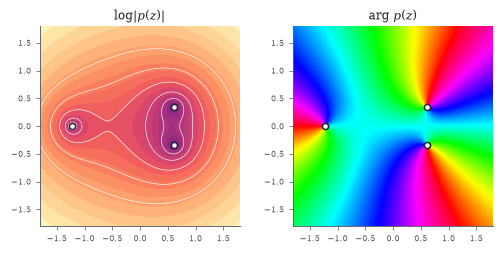

In [3]:
p = np.poly1d([1, 0, -1, 0.6])
xx, yy = np.meshgrid(np.linspace(-1.8, 1.8, 400), np.linspace(-1.8, 1.8, 400))
Z = p(xx + 1j * yy)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
axs[0].contourf(xx, yy, np.log(np.abs(Z) + 1e-3), levels=30, cmap="magma")
axs[0].contour(xx, yy, np.abs(Z), levels=[0.25, 0.5, 1, 2, 4], colors="white", linewidths=0.4)
axs[1].imshow(np.angle(Z), extent=(-1.8, 1.8, -1.8, 1.8), origin="lower", cmap="hsv")
for ax, t in zip(axs, [r"$\log|p(z)|$", r"$\arg\,p(z)$"]):
    r = p.roots; ax.plot(r.real, r.imag, "o", color="white", mec=INK, ms=4)
    ax.set_aspect("equal"); ax.set_title(t); ax.tick_params(labelsize=5)

Zeros of three random real polynomials of degree $11$ in the complex plane. The configuration is symmetric about the real axis: nonreal zeros come in conjugate pairs. With odd degree, at least one zero is real (on the axis); here several are.

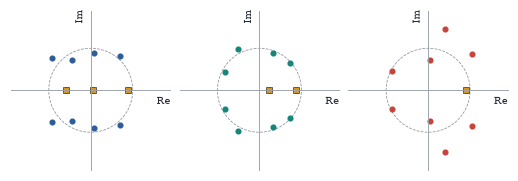

In [4]:
rng = np.random.default_rng(8)
fig, axs = plt.subplots(1, 3, figsize=(W, 1.6))
for ax, col in zip(axs, [BLUE, TEAL, RED]):
    r = np.roots(rng.normal(size=12))
    complex_plane(ax, 1.9, ticks=False)
    unit_circle(ax, lw=0.5)
    ax.plot(r.real, r.imag, "o", color=col, ms=3)
    real = np.abs(r.imag) < 1e-9
    ax.plot(r.real[real], r.imag[real], "s", color=GOLD, ms=4, mec=INK, mew=0.4)

Zeros of Wilkinson's polynomial $\prod_{k=1}^{20}(x-k)$ after random relative perturbations of size $10^{-10}$ in each coefficient (fifty trials, small dots). The zeros near $1$ to $7$ barely move; those in the middle of the range scatter far into the complex plane. Black squares, the unperturbed zeros.

Text(0, 0.5, 'Im')

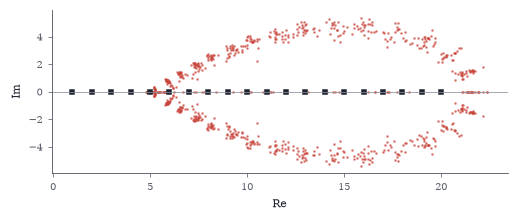

In [5]:
rng = np.random.default_rng(0)
c = np.poly(np.arange(1, 21))
fig, ax = plt.subplots(figsize=(W, 1.9))
for _ in range(50):
    r = np.roots(c * (1 + 1e-10 * rng.normal(size=c.size)))
    ax.plot(r.real, r.imag, ".", color=RED, ms=1.5, alpha=0.6)
ax.plot(np.arange(1, 21), np.zeros(20), "s", color=INK, ms=2.5)
ax.axhline(0, color=GRAY, lw=0.5); ax.set_xlabel("Re"); ax.set_ylabel("Im")

In [6]:
# Bezout: find r, s with r p + s q = 1 by solving the Sylvester system.
from numpy.polynomial import Polynomial as Poly
p = Poly([-1, 0, 1])                               # (z-1)(z+1)
q = Poly([6, -5, 1])                               # (z-2)(z-3): no zero in common with p
m, n = p.degree(), q.degree()
cols = [(Poly.basis(k) * p).coef for k in range(n)] + [(Poly.basis(k) * q).coef for k in range(m)]
S = np.zeros((m + n, m + n))
for j, c in enumerate(cols):
    S[:len(c), j] = c
rhs = np.zeros(m + n); rhs[0] = 1
sol = np.linalg.solve(S, rhs)
r, s = Poly(sol[:n]), Poly(sol[n:])
print("r =", r, "   s =", s)
print("r p + s q =", (r * p + s * q).trim(1e-12))
print("resultant (det of Sylvester matrix):", np.linalg.det(S).round(6))

r = 0.75 - 0.20833333·x    s = 0.29166667 + 0.20833333·x
r p + s q = 1.0
resultant (det of Sylvester matrix): 24.0


In [7]:
a = np.array([0.6, -1.0, 0.0])                         # p(z) = z^3 + 0 z^2 - z + 0.6  (coefficients a0, a1, a2)
m = len(a)
C = np.zeros((m, m)); C[1:, :-1] = np.eye(m - 1); C[:, -1] = -a
print("eigenvalues of C:", np.sort_complex(np.linalg.eigvals(C)).round(6))
print("np.roots        :", np.sort_complex(np.roots([1, a[2], a[1], a[0]])).round(6))

eigenvalues of C: [-1.221197+0.j        0.610598-0.344225j  0.610598+0.344225j]
np.roots        : [-1.221197+0.j        0.610598-0.344225j  0.610598+0.344225j]


Chebyshev polynomials $T_1,\dots,T_5$ oscillate between $-1$ and $1$ on $[-1,1]$. Their zeros (dots, for $T_5$) are the shadows of equally spaced points on a semicircle, so they crowd toward the ends of the interval.

(np.float64(-1.1), np.float64(1.1), np.float64(-0.05), np.float64(1.05))

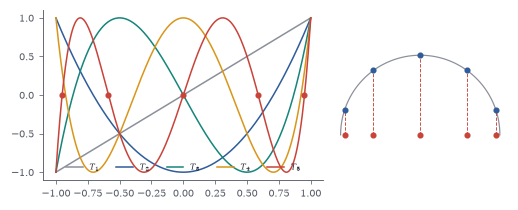

In [8]:
x = np.linspace(-1, 1, 400)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
for n, col in zip(range(1, 6), [GRAY, BLUE, TEAL, GOLD, RED]):
    axs[0].plot(x, np.cos(n * np.arccos(x)), color=col, lw=1, label=f"$T_{n}$")
z5 = np.cos((2 * np.arange(5) + 1) * np.pi / 10)
axs[0].plot(z5, 0 * z5, "o", color=RED, ms=3); axs[0].legend(ncol=5, fontsize=5.5, loc="lower center")
th = np.linspace(0, np.pi, 200); axs[1].plot(np.cos(th), np.sin(th), color=GRAY, lw=0.8)
for t in (2 * np.arange(5) + 1) * np.pi / 10:
    axs[1].plot([np.cos(t), np.cos(t)], [0, np.sin(t)], color=RED, lw=0.6, ls="--")
    axs[1].plot(np.cos(t), np.sin(t), "o", color=BLUE, ms=3)
axs[1].plot(z5, 0 * z5, "o", color=RED, ms=3); axs[1].set_aspect("equal"); axs[1].axis("off")

Lebesgue constants of polynomial interpolation on $n+1$ nodes. For equispaced nodes they grow exponentially (red); for Chebyshev nodes logarithmically (teal). This single number explains why the first interpolation fails and the second succeeds.

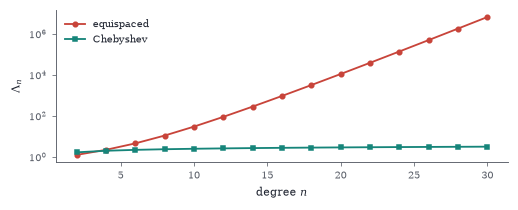

In [9]:
def lebesgue(nodes, xs=np.linspace(-1, 1, 3000)):
    L = np.ones((len(nodes), xs.size))
    for k, zk in enumerate(nodes):
        for j, zj in enumerate(nodes):
            if j != k:
                L[k] *= (xs - zj) / (zk - zj)
    return np.abs(L).sum(0).max()
ns = np.arange(2, 31, 2)
eq = [lebesgue(np.linspace(-1, 1, n + 1)) for n in ns]
ch = [lebesgue(np.cos((2 * np.arange(n + 1) + 1) * np.pi / (2 * n + 2))) for n in ns]
fig, ax = plt.subplots(figsize=(W, 1.8))
ax.semilogy(ns, eq, "o-", color=RED, ms=3, label="equispaced"); ax.semilogy(ns, ch, "s-", color=TEAL, ms=3, label="Chebyshev")
ax.set_xlabel("degree $n$"); ax.set_ylabel(r"$\Lambda_n$"); ax.legend()